# IT3091 Machine Learning: Bank Marketing (Guided Data Track, Banking & Finance)
**Primary lens:** Campaign response prediction  |  **Secondary lens:** Customer segment prioritisation  
**Unit of analysis:** 1 row = 1 phone contact with 1 client  
**Task:** Binary classification, predict `y` (subscribed to term deposit) using only information known BEFORE the call.  
**Stakeholder:** Marketing / Campaign Manager (limited call capacity, so needs a ranked call list)

Dataset: UCI Bank Marketing, `bank-additional-full.csv` (https://archive.ics.uci.edu/dataset/222/bank+marketing)

## 0. Setup and dataset fingerprint (Reproducibility)

In [1]:
import hashlib, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
warnings.filterwarnings("ignore")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid")

PATH = "bank-additional-full.csv"   # put the file next to this notebook
with open(PATH, "rb") as f:
    sha = hashlib.sha256(f.read()).hexdigest()
df_raw = pd.read_csv(PATH, sep=";")
print("SHA-256:", sha)
print("Rows, cols:", df_raw.shape)
df_raw.head()

SHA-256: 74adfc578bf77a7ff4bb1ba4a9f8709d9e3c6907342959c2c8416847e0afb4d8
Rows, cols: (41188, 21)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


## 1. Data dictionary

In [2]:
dictionary = pd.DataFrame([
 ["age","numeric","Client age (years)","Fairness-sensitive"],
 ["job","categorical","Type of job","Has 'unknown'"],
 ["marital","categorical","Marital status","Has 'unknown'; fairness-sensitive"],
 ["education","categorical","Education level","Has 'unknown'"],
 ["default","categorical","Has credit in default?","Mostly 'no'/'unknown', almost no 'yes'"],
 ["housing","categorical","Has housing loan?","Has 'unknown'"],
 ["loan","categorical","Has personal loan?","Has 'unknown'"],
 ["contact","categorical","Contact channel (cellular/telephone)","Known before call"],
 ["month","categorical","Last contact month","Seasonality"],
 ["day_of_week","categorical","Last contact weekday","Mon-Fri only"],
 ["duration","numeric","Last call duration (seconds)","LEAKAGE: unknown before the call, and duration=0 implies y='no'"],
 ["campaign","numeric","Contacts in this campaign for this client (incl. last)","Right-skewed, outliers"],
 ["pdays","numeric","Days since last contact in a PREVIOUS campaign","999 = never contacted"],
 ["previous","numeric","Contacts before this campaign","Mostly 0"],
 ["poutcome","categorical","Outcome of previous campaign","nonexistent/failure/success"],
 ["emp.var.rate","numeric","Employment variation rate (quarterly)","Macro, correlated"],
 ["cons.price.idx","numeric","Consumer price index (monthly)","Macro"],
 ["cons.conf.idx","numeric","Consumer confidence index (monthly)","Macro"],
 ["euribor3m","numeric","Euribor 3-month rate (daily)","Macro, highly correlated with emp.var.rate / nr.employed"],
 ["nr.employed","numeric","Number of employees (quarterly)","Macro, highly correlated"],
 ["y","binary (target)","Subscribed to term deposit?","Target, imbalanced"],
], columns=["Variable","Type","Meaning","Notes"])
dictionary

,Variable,Type,Meaning,Notes
0,age,numeric,Client age (years),Fairness-sensitive
1,job,categorical,Type of job,Has 'unknown'
2,marital,categorical,Marital status,Has 'unknown'; fairness-sensitive
3,education,categorical,Education level,Has 'unknown'
4,default,categorical,Has credit in default?,"Mostly 'no'/'unknown', almost no 'yes'"
5,housing,categorical,Has housing loan?,Has 'unknown'
6,loan,categorical,Has personal loan?,Has 'unknown'
7,contact,categorical,Contact channel (cellular/telephone),Known before call
8,month,categorical,Last contact month,Seasonality
9,day_of_week,categorical,Last contact weekday,Mon-Fri only


## 2. Data quality checks

In [3]:
print("Duplicates:", df_raw.duplicated().sum())
print("Missing (NaN):", df_raw.isna().sum().sum())
cat_cols_all = df_raw.select_dtypes("object").columns.drop("y")
unk = {c: int((df_raw[c]=="unknown").sum()) for c in cat_cols_all}
print("'unknown' counts:", {k:v for k,v in unk.items() if v>0})
print("pdays == 999 share: %.1f%%" % (100*(df_raw.pdays==999).mean()))
print("duration == 0 rows:", (df_raw.duration==0).sum(), "-> y values:", df_raw.loc[df_raw.duration==0,"y"].unique())
print(df_raw.y.value_counts(normalize=True).round(4))
print("Majority-class baseline accuracy: %.3f" % df_raw.y.value_counts(normalize=True).max())
df_raw.describe().T

Duplicates: 12
Missing (NaN): 0
'unknown' counts: {'job': 330, 'marital': 80, 'education': 1731, 'default': 8597, 'housing': 990, 'loan': 990}
pdays == 999 share: 96.3%
duration == 0 rows: 4 -> y values: ['no']
y
no     0.8873
yes    0.1127
Name: proportion, dtype: float64
Majority-class baseline accuracy: 0.887


,count,mean,std,min,25%,50%,75%,max
age,41188.0,40.024060,10.421250,17.000,32.000,38.000,47.000,98.000
duration,41188.0,258.285010,259.279249,0.000,102.000,180.000,319.000,4918.000
campaign,41188.0,2.567593,2.770014,1.000,1.000,2.000,3.000,56.000
pdays,41188.0,962.475454,186.910907,0.000,999.000,999.000,999.000,999.000
previous,41188.0,0.172963,0.494901,0.000,0.000,0.000,0.000,7.000
emp.var.rate,41188.0,0.081886,1.570960,-3.400,-1.800,1.100,1.400,1.400
cons.price.idx,41188.0,93.575664,0.578840,92.201,93.075,93.749,93.994,94.767
cons.conf.idx,41188.0,-40.502600,4.628198,-50.800,-42.700,-41.800,-36.400,-26.900
euribor3m,41188.0,3.621291,1.734447,0.634,1.344,4.857,4.961,5.045
nr.employed,41188.0,5167.035911,72.251528,4963.600,5099.100,5191.000,5228.100,5228.100


## 3. EDA

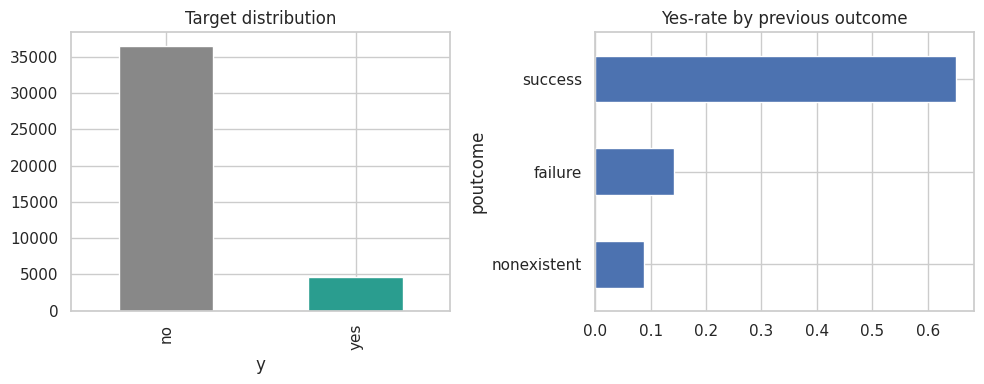

In [4]:
d = df_raw.copy()
d["target"] = (d.y=="yes").astype(int)

fig, ax = plt.subplots(1,2, figsize=(10,4))
d.y.value_counts().plot.bar(ax=ax[0], color=["#888","#2a9d8f"]); ax[0].set_title("Target distribution")
d.groupby("poutcome").target.mean().sort_values().plot.barh(ax=ax[1]); ax[1].set_title("Yes-rate by previous outcome")
plt.tight_layout(); plt.show()

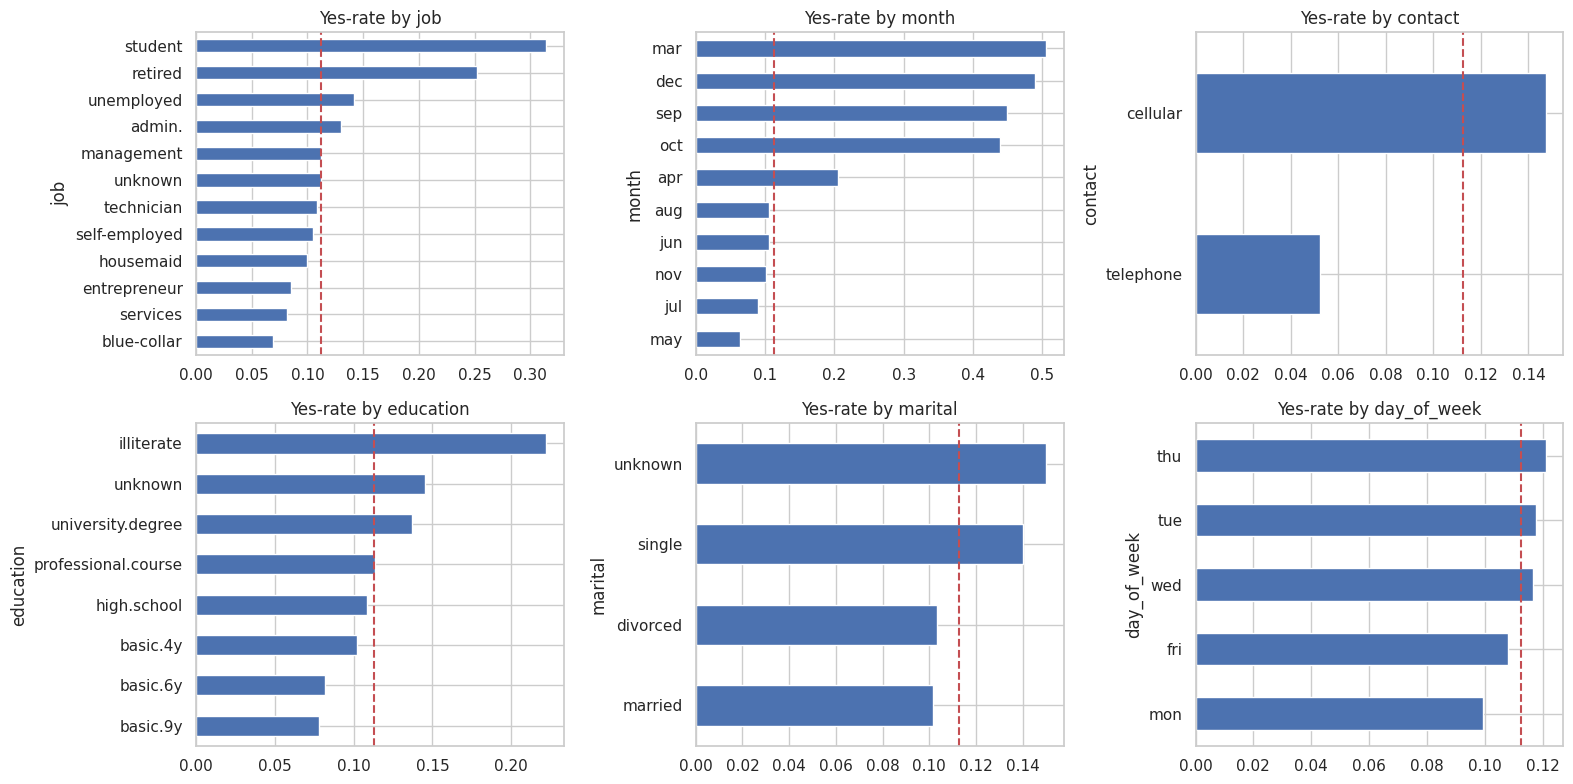

In [5]:
cats = ["job","month","contact","education","marital","day_of_week"]
fig, axes = plt.subplots(2,3, figsize=(16,8))
for a, c in zip(axes.ravel(), cats):
    d.groupby(c).target.mean().sort_values().plot.barh(ax=a)
    a.axvline(d.target.mean(), color="r", ls="--"); a.set_title("Yes-rate by "+c)
plt.tight_layout(); plt.show()

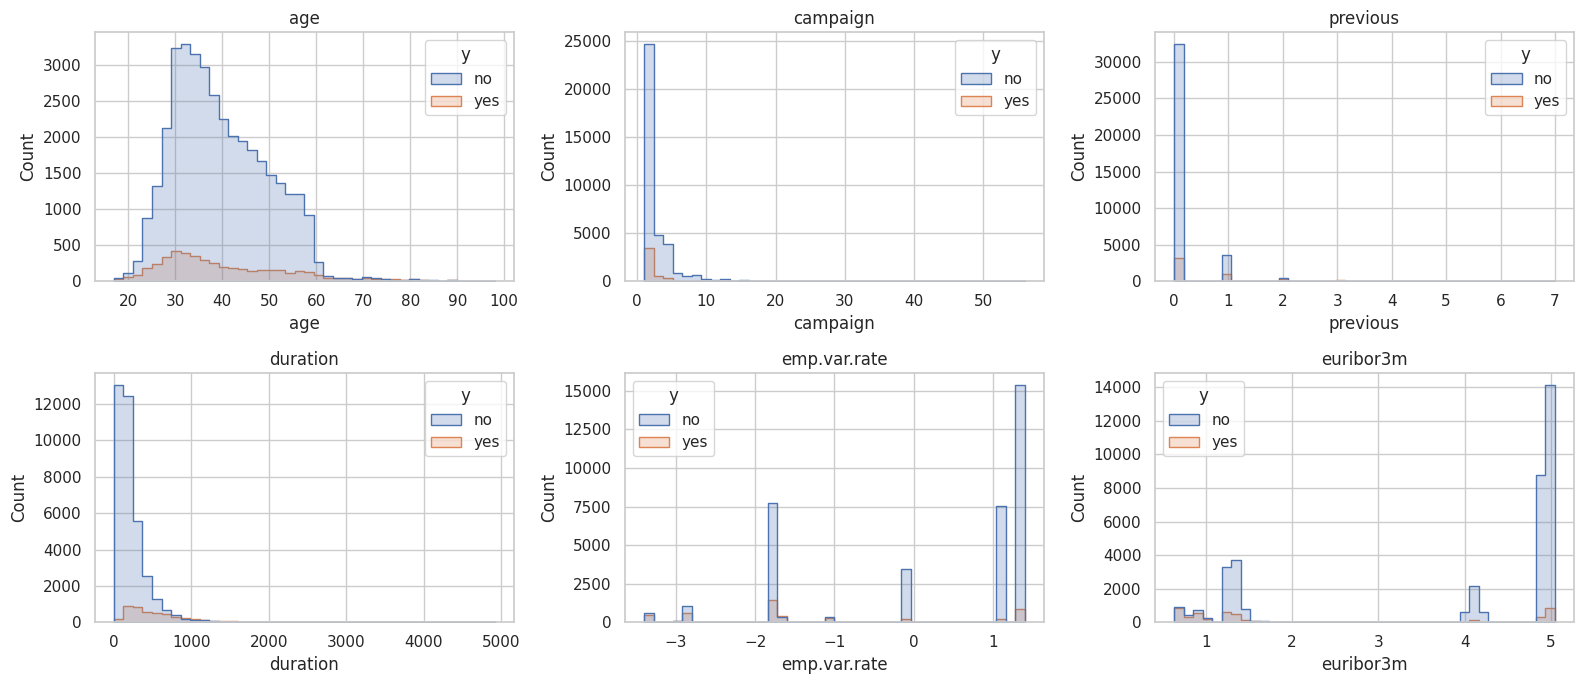

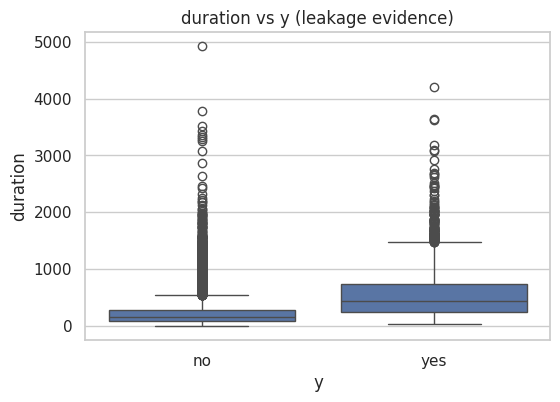

In [6]:
nums = ["age","campaign","previous","duration","emp.var.rate","euribor3m"]
fig, axes = plt.subplots(2,3, figsize=(16,7))
for a, c in zip(axes.ravel(), nums):
    sns.histplot(data=d, x=c, hue="y", bins=40, ax=a, element="step")
    a.set_title(c)
plt.tight_layout(); plt.show()

plt.figure(figsize=(6,4)); sns.boxplot(data=d, x="y", y="duration"); plt.title("duration vs y (leakage evidence)"); plt.show()

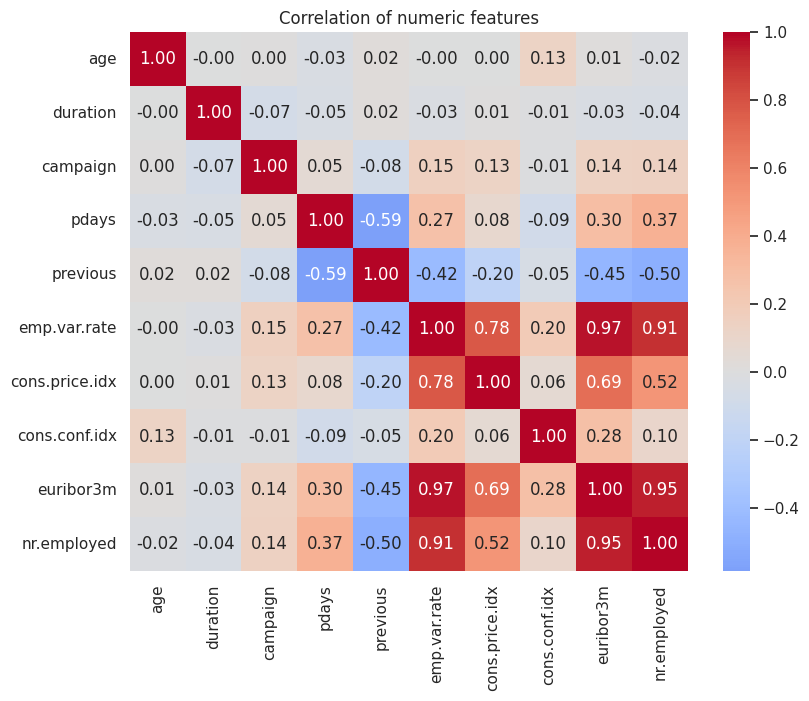

            mean  count
age_group              
(0, 25]    0.209   1666
(25, 35]   0.117  14847
(35, 45]   0.085  12844
(45, 55]   0.087   8249
(55, 65]   0.152   2963
(65, 100]  0.468    619
        mean  count
pdays              
False  0.638   1515
True   0.093  39673
campaign
1     0.130
2     0.115
3     0.107
4     0.094
5     0.075
6     0.077
7     0.060
8     0.042
9     0.060
10    0.036
Name: target, dtype: float64


In [7]:
num_all = d.select_dtypes("number").drop(columns="target")
plt.figure(figsize=(9,7))
sns.heatmap(num_all.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation of numeric features"); plt.show()

d["age_group"] = pd.cut(d.age, [0,25,35,45,55,65,100])
print(d.groupby("age_group").target.agg(["mean","count"]).round(3))
print(d.groupby(d.pdays==999).target.agg(["mean","count"]).round(3))
print(d.groupby(d.campaign.clip(upper=10)).target.mean().round(3))

### EDA insight log
Run the cells above, then **fill the numbers from your own outputs** (do not copy mine blindly; they are placeholders to verify).

In [8]:
eda_log = pd.DataFrame([
 [1,"~11% yes, ~89% no","Accuracy is misleading (majority baseline ~88.7%)","Use PR-AUC, recall/precision, lift; stratified splits; class_weight vs SMOTE"],
 [2,"duration strongly separates yes/no; duration=0 always 'no'","Not known before a call = leakage","Drop duration (optionally show with/without comparison)"],
 [3,"poutcome='success' has a much higher yes-rate (check number)","Strong, usable predictor","Keep; one-hot encode"],
 [4,"pdays=999 for ~96% of rows (check number)","Sentinel value would distort numeric scaling","Replace with prev_contacted flag; drop pdays"],
 [5,"'unknown' in job/marital/education/default/housing/loan","Not true missing; may carry signal","Keep as its own category"],
 [6,"campaign heavily right-skewed; many contacts reduce yes-rate","Outliers can hurt linear models","Cap at 99th percentile or keep for trees (decide + log)"],
 [7,"emp.var.rate, euribor3m, nr.employed correlation > 0.9","Multicollinearity; unstable LR coefficients","Keep for trees; consider dropping one for LR; note in limitations"],
 [8,"Yes-rate varies by month/age group (check graphs)","Seasonality / customer segments useful for prioritisation","Keep; use in decile profiling (secondary lens)"],
], columns=["#","Observation","Why it matters","Action taken"])
eda_log

,#,Observation,Why it matters,Action taken
0,1,"~11% yes, ~89% no",Accuracy is misleading (majority baseline ~88.7%),"Use PR-AUC, recall/precision, lift; stratified..."
1,2,duration strongly separates yes/no; duration=0...,Not known before a call = leakage,Drop duration (optionally show with/without co...
2,3,poutcome='success' has a much higher yes-rate ...,"Strong, usable predictor",Keep; one-hot encode
3,4,pdays=999 for ~96% of rows (check number),Sentinel value would distort numeric scaling,Replace with prev_contacted flag; drop pdays
4,5,'unknown' in job/marital/education/default/hou...,Not true missing; may carry signal,Keep as its own category
5,6,campaign heavily right-skewed; many contacts r...,Outliers can hurt linear models,Cap at 99th percentile or keep for trees (deci...
6,7,"emp.var.rate, euribor3m, nr.employed correlati...",Multicollinearity; unstable LR coefficients,Keep for trees; consider dropping one for LR; ...
7,8,Yes-rate varies by month/age group (check graphs),Seasonality / customer segments useful for pri...,Keep; use in decile profiling (secondary lens)


## 4. Preprocessing and feature engineering

In [9]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

df = df_raw.drop_duplicates().copy()
print("After dedup:", df.shape)

df["prev_contacted"] = (df["pdays"] != 999).astype(int)
df = df.drop(columns=["pdays", "duration"])          # sentinel + leakage
df["campaign"] = df["campaign"].clip(upper=10)       # cap outliers at 10 (fixed value from EDA)
y = (df["y"] == "yes").astype(int)
X = df.drop(columns="y")

# Hold-out test set: touched ONCE at the very end
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print("Train:", X_train.shape, "yes-rate %.3f" % y_train.mean())
print("Test :", X_test.shape,  "yes-rate %.3f" % y_test.mean())

num_cols = X.select_dtypes("number").columns.tolist()
cat_cols = X.select_dtypes("object").columns.tolist()
preprocess = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
], sparse_threshold=0)   # always dense output (HistGradientBoosting needs dense)
# NOTE: fitted only inside CV/Pipeline later, so no leakage from validation/test folds.
print("Numeric:", num_cols); print("Categorical:", cat_cols)

After dedup: (41176, 21)
Train: (32940, 19) yes-rate 0.113
Test : (8236, 19) yes-rate 0.113
Numeric: ['age', 'campaign', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'prev_contacted']
Categorical: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']


In [10]:
prep_log = pd.DataFrame([
 ["Duplicates","Removed ~12 exact duplicate rows","Duplicates inflate CV scores"],
 ["Leakage","Dropped duration","Unknown before the call; realistic model must exclude it"],
 ["Sentinel value","pdays 999 -> prev_contacted flag","999 is a code, not a distance"],
 ["Unknown category","Kept as separate level","Informative; imputation would invent values"],
 ["Categorical encoding","One-hot (handle_unknown='ignore')","Nominal variables, no order"],
 ["Scaling","StandardScaler on numerics","Needed for LR; harmless for trees"],
 ["Outliers","campaign: decide (cap vs keep) and record here","Trees are robust; LR is sensitive"],
 ["Imbalance","class_weight vs SMOTE (inside imblearn Pipeline), compared in modelling","Prevent leakage, pick by PR-AUC"],
 ["Split","Stratified 80/20 + stratified 5-fold CV on train","Preserve 11% rate; test set used once"],
], columns=["Issue","Decision","Reason"])
prep_log

,Issue,Decision,Reason
0,Duplicates,Removed ~12 exact duplicate rows,Duplicates inflate CV scores
1,Leakage,Dropped duration,Unknown before the call; realistic model must ...
2,Sentinel value,pdays 999 -> prev_contacted flag,"999 is a code, not a distance"
3,Unknown category,Kept as separate level,Informative; imputation would invent values
4,Categorical encoding,One-hot (handle_unknown='ignore'),"Nominal variables, no order"
5,Scaling,StandardScaler on numerics,Needed for LR; harmless for trees
6,Outliers,campaign: decide (cap vs keep) and record here,Trees are robust; LR is sensitive
7,Imbalance,class_weight vs SMOTE (inside imblearn Pipelin...,"Prevent leakage, pick by PR-AUC"
8,Split,Stratified 80/20 + stratified 5-fold CV on train,Preserve 11% rate; test set used once


## 5. Decision log (add entries as you go)

In [11]:
decision_log = pd.DataFrame([
 ["D1","Primary lens","Response prediction / segment prioritisation / profile analysis","Response prediction (+ prioritisation as secondary)","Direct link to call-capacity decision; secondary reuses model scores"],
 ["D2","Handle duration","Keep / drop / compare both","Drop (show comparison optionally)","Unavailable pre-call; would overstate performance"],
 ["D3","Handle 'unknown'","Impute / drop rows / own category","Own category","Keeps rows; may carry signal"],
 ["D4","pdays=999","Keep numeric / flag","Flag","Sentinel value"],
 ["D5","Split","Random stratified / time-based","Stratified (state limitation; mention time-based as future work)","Simpler, time budget; limitation noted"],
 ["D6","Main metric","Accuracy / ROC-AUC / PR-AUC / lift","PR-AUC + lift@20%","Imbalanced; ranking use-case"],
], columns=["ID","Decision","Options considered","Choice","Reason / evidence"])
decision_log

,ID,Decision,Options considered,Choice,Reason / evidence
0,D1,Primary lens,Response prediction / segment prioritisation /...,Response prediction (+ prioritisation as secon...,Direct link to call-capacity decision; seconda...
1,D2,Handle duration,Keep / drop / compare both,Drop (show comparison optionally),Unavailable pre-call; would overstate performance
2,D3,Handle 'unknown',Impute / drop rows / own category,Own category,Keeps rows; may carry signal
3,D4,pdays=999,Keep numeric / flag,Flag,Sentinel value
4,D5,Split,Random stratified / time-based,Stratified (state limitation; mention time-bas...,"Simpler, time budget; limitation noted"
5,D6,Main metric,Accuracy / ROC-AUC / PR-AUC / lift,PR-AUC + lift@20%,Imbalanced; ranking use-case


# PART 2: Modelling and Evaluation

## 6. Setup for modelling

In [12]:
import sys, subprocess, sklearn
try:
    import imblearn
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "imbalanced-learn"])
    import imblearn
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_predict, RandomizedSearchCV
from sklearn.metrics import (roc_auc_score, average_precision_score, precision_score, recall_score,
                             f1_score, confusion_matrix, precision_recall_curve, roc_curve)
from sklearn.inspection import permutation_importance
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

RS = RANDOM_STATE
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RS)
scoring = {"roc_auc": "roc_auc", "pr_auc": "average_precision",
           "precision": "precision", "recall": "recall", "f1": "f1"}

def cv_summary(pipe, X, y):
    s = cross_validate(pipe, X, y, cv=cv, scoring=scoring, n_jobs=1)
    out = {}
    for k in scoring:
        out[k + "_mean"] = s["test_" + k].mean()
        out[k + "_std"] = s["test_" + k].std()
    return out
print("scikit-learn", sklearn.__version__, "| train:", X_train.shape, "| test (untouched):", X_test.shape)

scikit-learn 1.6.1 | train: (32940, 19) | test (untouched): (8236, 19)


## 7. Model comparison with cross-validation (training set only)
Baseline + four alternatives. All preprocessing is inside a `Pipeline`, so scaling and encoding are fitted on each training fold only (no leakage).
`class_weight` is used for Logistic Regression, Decision Tree and Random Forest because only about 11% of rows are 'yes'.

In [13]:
models = {
    "Dummy (prior)":       DummyClassifier(strategy="prior"),
    "Logistic Regression": LogisticRegression(max_iter=2000, class_weight="balanced"),
    "Decision Tree":       DecisionTreeClassifier(max_depth=6, min_samples_leaf=50, class_weight="balanced", random_state=RS),
    "Random Forest":       RandomForestClassifier(n_estimators=300, min_samples_leaf=5, class_weight="balanced_subsample", n_jobs=-1, random_state=RS),
    "Gradient Boosting (HGB)": HistGradientBoostingClassifier(random_state=RS),
}
rows = {}
for name, clf in models.items():
    pipe = Pipeline([("pre", preprocess), ("clf", clf)])
    rows[name] = cv_summary(pipe, X_train, y_train)
    print("done:", name)
cv_results = pd.DataFrame(rows).T
show = cv_results[[c for c in cv_results.columns if c.endswith("_mean")]].round(3)
show.columns = ["ROC-AUC", "PR-AUC", "Precision", "Recall", "F1"]
show

done: Dummy (prior)
done: Logistic Regression
done: Decision Tree
done: Random Forest
done: Gradient Boosting (HGB)


,ROC-AUC,PR-AUC,Precision,Recall,F1
Dummy (prior),0.500,0.113,0.000,0.000,0.000
Logistic Regression,0.790,0.446,0.353,0.623,0.450
Decision Tree,0.781,0.420,0.353,0.610,0.445
Random Forest,0.794,0.465,0.432,0.583,0.496
Gradient Boosting (HGB),0.799,0.463,0.647,0.260,0.371


## 8. Imbalance handling: none vs class_weight vs SMOTE
SMOTE sits **inside** the imblearn pipeline, so synthetic rows are created only from the training part of each fold. Choice is made on PR-AUC (threshold-free) plus recall/precision.

In [14]:
lr = lambda **kw: LogisticRegression(max_iter=2000, **kw)
imb = {
    "LR: no handling":   Pipeline([("pre", preprocess), ("clf", lr())]),
    "LR: class_weight":  Pipeline([("pre", preprocess), ("clf", lr(class_weight="balanced"))]),
    "LR: SMOTE":         ImbPipeline([("pre", preprocess), ("smote", SMOTE(random_state=RS)), ("clf", lr())]),
    "HGB: no handling":  Pipeline([("pre", preprocess), ("clf", HistGradientBoostingClassifier(random_state=RS))]),
    "HGB: SMOTE":        ImbPipeline([("pre", preprocess), ("smote", SMOTE(random_state=RS)), ("clf", HistGradientBoostingClassifier(random_state=RS))]),
}
imb_rows = {n: cv_summary(p, X_train, y_train) for n, p in imb.items()}
imb_results = pd.DataFrame(imb_rows).T
imb_show = imb_results[[c for c in imb_results.columns if c.endswith("_mean")]].round(3)
imb_show.columns = ["ROC-AUC", "PR-AUC", "Precision", "Recall", "F1"]
imb_show

,ROC-AUC,PR-AUC,Precision,Recall,F1
LR: no handling,0.789,0.451,0.663,0.230,0.341
LR: class_weight,0.790,0.446,0.353,0.623,0.450
LR: SMOTE,0.787,0.444,0.342,0.622,0.442
HGB: no handling,0.799,0.463,0.647,0.260,0.371
HGB: SMOTE,0.794,0.453,0.569,0.327,0.415


## 9. Leakage demonstration: with vs without `duration`
Shows why `duration` was dropped: it makes the model look much better than it could ever be at call time.

In [15]:
dur = df_raw.drop_duplicates()["duration"]
X_train_leak = X_train.assign(duration=dur.loc[X_train.index].values)
pre_leak = ColumnTransformer([
    ("num", StandardScaler(), num_cols + ["duration"]),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
], sparse_threshold=0)
hgb = lambda: HistGradientBoostingClassifier(random_state=RS)
leak = pd.DataFrame({
    "HGB WITHOUT duration (realistic)": cv_summary(Pipeline([("pre", preprocess), ("clf", hgb())]), X_train, y_train),
    "HGB WITH duration (leaky)":        cv_summary(Pipeline([("pre", pre_leak), ("clf", hgb())]), X_train_leak, y_train),
}).T
leak_show = leak[["roc_auc_mean", "pr_auc_mean"]].round(3)
leak_show.columns = ["ROC-AUC", "PR-AUC"]
leak_show

,ROC-AUC,PR-AUC
HGB WITHOUT duration (realistic),0.799,0.463
HGB WITH duration (leaky),0.950,0.668


## 10. Light hyperparameter tuning of the best family (HGB)
Small random search (10 candidates), optimised for PR-AUC, using the same stratified 5-fold CV on the training set.

In [16]:
hgb_pipe = Pipeline([("pre", preprocess), ("clf", HistGradientBoostingClassifier(random_state=RS))])
param_dist = {
    "clf__learning_rate": [0.03, 0.05, 0.1],
    "clf__max_leaf_nodes": [15, 31, 63],
    "clf__min_samples_leaf": [20, 50, 100],
    "clf__l2_regularization": [0, 1, 10],
    "clf__max_iter": [150, 300],
}
search = RandomizedSearchCV(hgb_pipe, param_dist, n_iter=10, scoring="average_precision",
                            cv=cv, random_state=RS, n_jobs=-1, refit=True)
search.fit(X_train, y_train)
print("Best params:", search.best_params_)
print("Best CV PR-AUC: %.4f" % search.best_score_)

cv_results.loc["HGB (tuned)"] = cv_summary(search.best_estimator_, X_train, y_train)
show = cv_results[[c for c in cv_results.columns if c.endswith("_mean")]].round(3)
show.columns = ["ROC-AUC", "PR-AUC", "Precision", "Recall", "F1"]
show

Best params: {'clf__min_samples_leaf': 50, 'clf__max_leaf_nodes': 15, 'clf__max_iter': 150, 'clf__learning_rate': 0.03, 'clf__l2_regularization': 10}
Best CV PR-AUC: 0.4692


,ROC-AUC,PR-AUC,Precision,Recall,F1
Dummy (prior),0.500,0.113,0.000,0.000,0.000
Logistic Regression,0.790,0.446,0.353,0.623,0.450
Decision Tree,0.781,0.420,0.353,0.610,0.445
Random Forest,0.794,0.465,0.432,0.583,0.496
Gradient Boosting (HGB),0.799,0.463,0.647,0.260,0.371
HGB (tuned),0.801,0.469,0.670,0.244,0.357


Model chosen by CV PR-AUC: HGB (tuned)


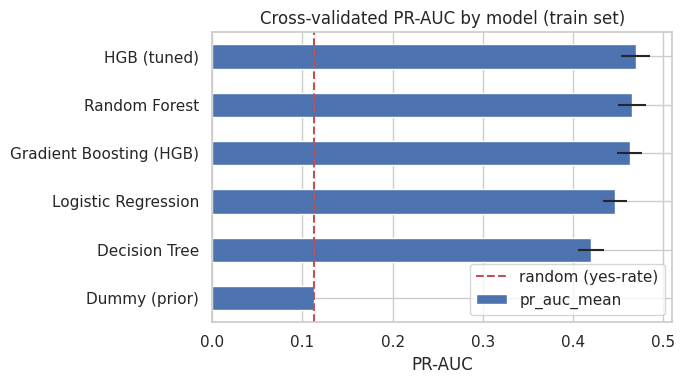

In [17]:
cand = cv_results.drop(index="Dummy (prior)")
best_name = cand["pr_auc_mean"].idxmax()
print("Model chosen by CV PR-AUC:", best_name)
fig, ax = plt.subplots(figsize=(7, 4))
cv_results["pr_auc_mean"].sort_values().plot.barh(ax=ax, xerr=cv_results["pr_auc_std"].reindex(cv_results["pr_auc_mean"].sort_values().index))
ax.axvline(y_train.mean(), color="r", ls="--", label="random (yes-rate)"); ax.legend()
ax.set_title("Cross-validated PR-AUC by model (train set)"); ax.set_xlabel("PR-AUC"); plt.tight_layout(); plt.show()

## 11. Final fit and hold-out test evaluation (used once)
All models are refitted on the full training set and scored once on the untouched test set. The final model was chosen from the CV table above, not from these test scores.

,ROC-AUC,PR-AUC
Dummy (prior),0.500,0.113
Logistic Regression,0.800,0.446
Decision Tree,0.800,0.460
Random Forest,0.806,0.484
Gradient Boosting (HGB),0.812,0.490
HGB (tuned),0.814,0.493


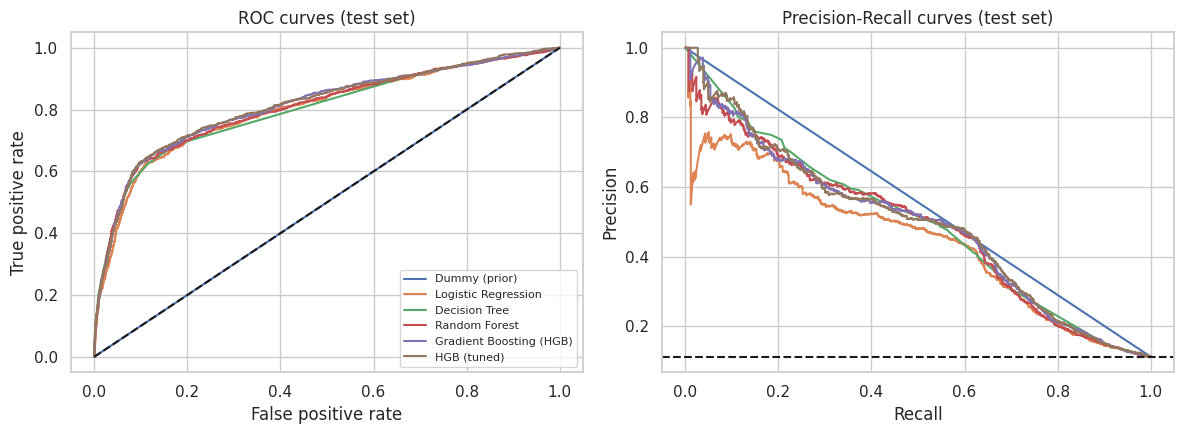

In [18]:
final = {n: Pipeline([("pre", preprocess), ("clf", clone(c))]) for n, c in models.items()}
final["HGB (tuned)"] = search.best_estimator_
test_rows, probas = {}, {}
for n, p in final.items():
    if n != "HGB (tuned)":
        p.fit(X_train, y_train)
    pr = p.predict_proba(X_test)[:, 1]
    probas[n] = pr
    test_rows[n] = {"ROC-AUC": roc_auc_score(y_test, pr), "PR-AUC": average_precision_score(y_test, pr)}
test_results = pd.DataFrame(test_rows).T.round(3)
display(test_results)

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
for n, pr in probas.items():
    fpr, tpr, _ = roc_curve(y_test, pr); ax[0].plot(fpr, tpr, label=n)
    pre_, rec_, _ = precision_recall_curve(y_test, pr); ax[1].plot(rec_, pre_, label=n)
ax[0].plot([0, 1], [0, 1], "k--"); ax[0].set_title("ROC curves (test set)"); ax[0].set_xlabel("False positive rate"); ax[0].set_ylabel("True positive rate")
ax[1].axhline(y_test.mean(), color="k", ls="--"); ax[1].set_title("Precision-Recall curves (test set)"); ax[1].set_xlabel("Recall"); ax[1].set_ylabel("Precision")
ax[0].legend(fontsize=8); plt.tight_layout(); plt.show()

## 12. Business threshold (cost-based), chosen on out-of-fold predictions
**Assumptions (explicit):** one call costs 1 unit; one successful subscription is worth 10 units. Profit = 10 x subscribers reached - 1 x calls made.
The threshold is chosen on **out-of-fold training predictions**, never on the test set. A sensitivity check varies the subscription value.

Chosen threshold: 0.11  | OOF profit per customer: 0.523  (call everyone: 0.127)


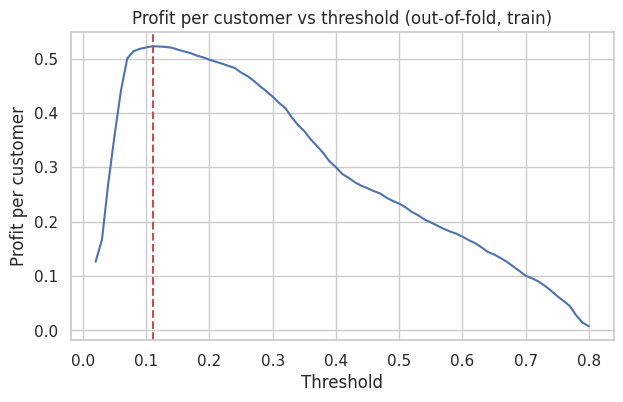

,best threshold,profit/customer (model),profit/customer (call all)
subscription value,,,
5,0.17,0.178,-0.437
10,0.11,0.523,0.127
20,0.05,1.361,1.253


In [19]:
best_pipe = final[best_name]
oof = cross_val_predict(clone(best_pipe), X_train, y_train, cv=cv, method="predict_proba")[:, 1]
CALL_COST, SUB_VALUE = 1, 10

def profit(y_true, proba, thr, value=SUB_VALUE, cost=CALL_COST):
    pred = proba >= thr
    return value * ((pred) & (np.asarray(y_true) == 1)).sum() - cost * pred.sum()

thrs = np.linspace(0.02, 0.80, 79)
prof = np.array([profit(y_train, oof, t) for t in thrs]) / len(y_train)
THR = thrs[prof.argmax()]
print("Chosen threshold: %.2f  | OOF profit per customer: %.3f  (call everyone: %.3f)" % (THR, prof.max(), SUB_VALUE * y_train.mean() - CALL_COST))

plt.figure(figsize=(7, 4)); plt.plot(thrs, prof); plt.axvline(THR, color="r", ls="--")
plt.title("Profit per customer vs threshold (out-of-fold, train)"); plt.xlabel("Threshold"); plt.ylabel("Profit per customer"); plt.show()

sens = {}
for v in [5, 10, 20]:
    p_ = np.array([profit(y_train, oof, t, value=v) for t in thrs]) / len(y_train)
    sens[v] = {"best threshold": round(thrs[p_.argmax()], 2), "profit/customer (model)": round(p_.max(), 3),
               "profit/customer (call all)": round(v * y_train.mean() - CALL_COST, 3)}
pd.DataFrame(sens).T.rename_axis("subscription value")

Final model: HGB (tuned) | threshold 0.11
Precision 0.379 | Recall 0.670 | F1 0.484
Calls made: 1642 of 8236 customers (19.9%)


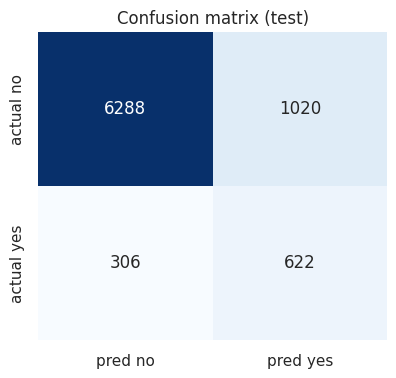

Profit per 1000 customers -> model: 556 | call everyone: 127


In [20]:
proba_test = probas[best_name]
pred_test = (proba_test >= THR).astype(int)
cm = confusion_matrix(y_test, pred_test)
print("Final model:", best_name, "| threshold %.2f" % THR)
print("Precision %.3f | Recall %.3f | F1 %.3f" % (precision_score(y_test, pred_test), recall_score(y_test, pred_test), f1_score(y_test, pred_test)))
print("Calls made: %d of %d customers (%.1f%%)" % (pred_test.sum(), len(y_test), 100 * pred_test.mean()))

plt.figure(figsize=(4.5, 4)); sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
    xticklabels=["pred no", "pred yes"], yticklabels=["actual no", "actual yes"]); plt.title("Confusion matrix (test)"); plt.show()

n = len(y_test)
model_p = profit(y_test, proba_test, THR) / n * 1000
all_p = (SUB_VALUE * y_test.mean() - CALL_COST) * 1000
print("Profit per 1000 customers -> model: %.0f | call everyone: %.0f" % (model_p, all_p))

## 13. Gains and lift (test set): secondary lens, customer prioritisation
Customers are ranked by predicted probability and split into 10 equal groups (deciles). Decile 1 = most likely to subscribe.

,customers,subscribers,mean_prob,yes_rate,lift,cum_capture
decile,,,,,,
1,824,430,0.491,0.522,4.631,0.463
2,824,193,0.202,0.234,2.079,0.671
3,823,69,0.085,0.084,0.744,0.746
4,824,42,0.067,0.051,0.452,0.791
5,823,42,0.060,0.051,0.453,0.836
6,824,42,0.055,0.051,0.452,0.881
7,823,26,0.048,0.032,0.280,0.909
8,824,31,0.042,0.038,0.334,0.943
9,823,33,0.035,0.040,0.356,0.978


Top 10% of customers capture 46.3% of all subscribers (lift 4.63)
Top 20% of customers capture 67.1% of all subscribers (cumulative lift 3.36)


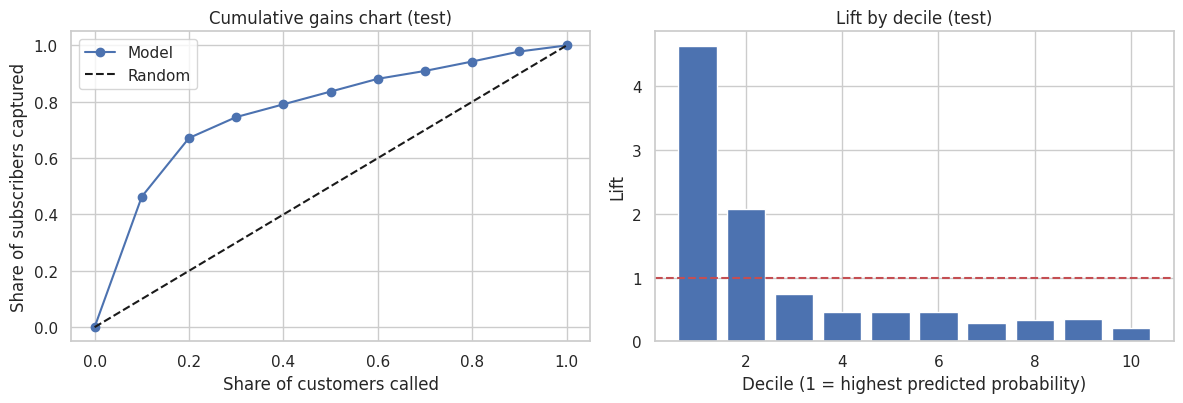

In [21]:
dec = pd.DataFrame({"y": y_test.values, "p": proba_test})
dec["decile"] = pd.qcut(dec["p"].rank(method="first", ascending=False), 10, labels=range(1, 11))
g = dec.groupby("decile", observed=False).agg(customers=("y", "size"), subscribers=("y", "sum"), mean_prob=("p", "mean"))
g["yes_rate"] = g["subscribers"] / g["customers"]
g["lift"] = g["yes_rate"] / dec["y"].mean()
g["cum_capture"] = g["subscribers"].cumsum() / dec["y"].sum()
display(g.round(3))
print("Top 10%% of customers capture %.1f%% of all subscribers (lift %.2f)" % (100 * g.loc[1, "cum_capture"], g.loc[1, "lift"]))
print("Top 20%% of customers capture %.1f%% of all subscribers (cumulative lift %.2f)" % (100 * g.loc[2, "cum_capture"], g.loc[2, "cum_capture"] / 0.2))

fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
x = np.arange(0, 11)
ax[0].plot(x / 10, np.r_[0, g["cum_capture"].values], marker="o", label="Model"); ax[0].plot([0, 1], [0, 1], "k--", label="Random")
ax[0].set_title("Cumulative gains chart (test)"); ax[0].set_xlabel("Share of customers called"); ax[0].set_ylabel("Share of subscribers captured"); ax[0].legend()
ax[1].bar(g.index.astype(int), g["lift"]); ax[1].axhline(1, color="r", ls="--")
ax[1].set_title("Lift by decile (test)"); ax[1].set_xlabel("Decile (1 = highest predicted probability)"); ax[1].set_ylabel("Lift")
plt.tight_layout(); plt.show()


== job


,share_in_top20,share_overall,ratio
job,,,
admin.,0.332,0.261,1.27
technician,0.147,0.160,0.92
retired,0.096,0.040,2.40
blue-collar,0.091,0.220,0.41
student,0.072,0.022,3.27
management,0.069,0.071,0.97
services,0.059,0.095,0.62
self-employed,0.041,0.037,1.11



== month


,share_in_top20,share_overall,ratio
month,,,
apr,0.223,0.066,3.38
may,0.172,0.334,0.51
jun,0.120,0.130,0.92
aug,0.115,0.148,0.78
oct,0.083,0.017,4.88
nov,0.075,0.102,0.74
mar,0.069,0.014,4.93
sep,0.066,0.013,5.08



== poutcome


,share_in_top20,share_overall,ratio
poutcome,,,
nonexistent,0.661,0.864,0.77
failure,0.173,0.102,1.70
success,0.166,0.034,4.88



== contact


,share_in_top20,share_overall,ratio
contact,,,
cellular,0.881,0.631,1.40
telephone,0.119,0.369,0.32



== age_group


,share_in_top20,share_overall,ratio
age_group,,,
"(25, 35]",0.395,0.359,1.10
"(35, 45]",0.198,0.315,0.63
"(45, 55]",0.141,0.201,0.70
"(55, 65]",0.101,0.072,1.40
"(0, 25]",0.098,0.040,2.45
"(65, 100]",0.067,0.013,5.15


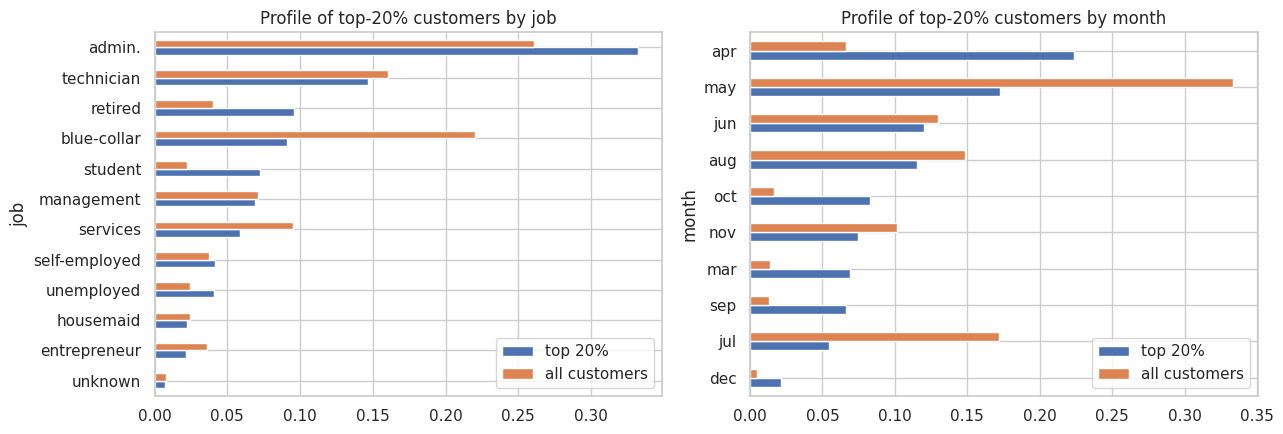

In [22]:
# Who is in the top 20%? (segment profile)
Xt = X_test.reset_index(drop=True).copy()
Xt["age_group"] = pd.cut(Xt["age"], [0, 25, 35, 45, 55, 65, 100]).astype(str)
top20 = dec["p"].rank(method="first", ascending=False) <= 0.2 * len(dec)
for col in ["job", "month", "poutcome", "contact", "age_group"]:
    t = pd.DataFrame({"share_in_top20": Xt.loc[top20, col].value_counts(normalize=True),
                      "share_overall": Xt[col].value_counts(normalize=True)}).fillna(0).round(3)
    t["ratio"] = (t["share_in_top20"] / t["share_overall"]).round(2)
    print("\n== " + col); display(t.sort_values("share_in_top20", ascending=False).head(8))

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for a, col in zip(ax, ["job", "month"]):
    pd.DataFrame({"top 20%": Xt.loc[top20, col].value_counts(normalize=True),
                  "all customers": Xt[col].value_counts(normalize=True)}).fillna(0).sort_values("top 20%").plot.barh(ax=a)
    a.set_title("Profile of top-20% customers by " + col)
plt.tight_layout(); plt.show()

## 14. Explainability: permutation importance (test set)

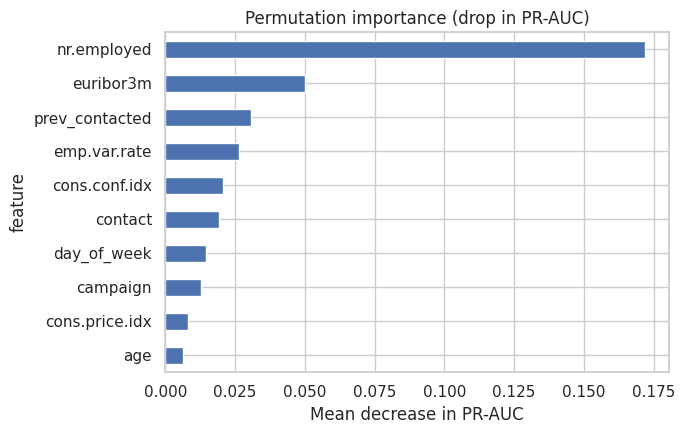

,feature,importance,std
17,nr.employed,0.1719,0.0111
16,euribor3m,0.0500,0.0029
18,prev_contacted,0.0309,0.0065
13,emp.var.rate,0.0264,0.0012
15,cons.conf.idx,0.0208,0.0020
7,contact,0.0191,0.0027
9,day_of_week,0.0145,0.0017
10,campaign,0.0128,0.0018
14,cons.price.idx,0.0082,0.0008
0,age,0.0065,0.0014


In [23]:
pi = permutation_importance(best_pipe, X_test, y_test, scoring="average_precision", n_repeats=5, random_state=RS, n_jobs=-1)
imp = pd.DataFrame({"feature": X_test.columns, "importance": pi.importances_mean, "std": pi.importances_std}).sort_values("importance")
imp.tail(10).plot.barh(x="feature", y="importance", xerr=imp.tail(10)["std"], legend=False, figsize=(7, 4.5))
plt.title("Permutation importance (drop in PR-AUC)"); plt.xlabel("Mean decrease in PR-AUC"); plt.tight_layout(); plt.show()
imp.sort_values("importance", ascending=False).round(4).head(10)

## 15. Fairness check (responsible AI)
`age` and `marital` are sensitive. This checks whether the call list would systematically under-select some groups.

In [24]:
fair = Xt.assign(selected=top20.values, y=y_test.values)
for col in ["age_group", "marital"]:
    f = fair.groupby(col).agg(customers=("selected", "size"), selected_share=("selected", "mean"), actual_yes_rate=("y", "mean")).round(3)
    print("\n== " + col + " (overall selection rate = 0.200)"); display(f)


== age_group (overall selection rate = 0.200)


,customers,selected_share,actual_yes_rate
age_group,,,
"(0, 25]",328,0.494,0.189
"(25, 35]",2953,0.220,0.124
"(35, 45]",2594,0.126,0.091
"(45, 55]",1655,0.141,0.075
"(55, 65]",596,0.279,0.143
"(65, 100]",110,1.000,0.500



== marital (overall selection rate = 0.200)


,customers,selected_share,actual_yes_rate
marital,,,
divorced,911,0.169,0.114
married,5006,0.169,0.098
single,2307,0.280,0.143
unknown,12,0.083,0.083


## 16. Reproducibility information

In [25]:
import platform, numpy, pandas, matplotlib, seaborn
print("Python", platform.python_version(), "| numpy", numpy.__version__, "| pandas", pandas.__version__,
      "| scikit-learn", sklearn.__version__, "| imbalanced-learn", imblearn.__version__)
print("Dataset SHA-256:", sha)
print("Random seed:", RS)

Python 3.13.16 | numpy 2.1.3 | pandas 2.2.3 | scikit-learn 1.6.1 | imbalanced-learn 0.14.2
Dataset SHA-256: 74adfc578bf77a7ff4bb1ba4a9f8709d9e3c6907342959c2c8416847e0afb4d8
Random seed: 42
